In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l2


In [4]:
train = pd.read_csv(r"C:\Users\admin\Downloads\Dataset-20261112T113230Z-1-001\Dataset\Fashion\fashion-mnist_train.csv")
test = pd.read_csv(r"C:\Users\admin\Downloads\Dataset-20261112T113230Z-1-001\Dataset\Fashion\fashion-mnist_test.csv")

In [5]:
x_train = train.drop("label", axis=1).values
y_train = train["label"].values

x_test = test.drop("label", axis=1).values
y_test = test["label"].values

In [6]:
x_train = x_train/255.0
x_test = x_test/255.0

In [7]:
x_train = x_train.reshape(-1,28,28)
x_test = x_test.reshape(-1,28,28)

print("Dataset Loaded Successfully....")
print("Training Dataset : ",x_train.shape)
print("Testing Dataset : ",x_test.shape)

Dataset Loaded Successfully....
Training Dataset :  (60000, 28, 28)
Testing Dataset :  (10000, 28, 28)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8164 - loss: 0.5210 - val_accuracy: 0.8468 - val_loss: 0.4277
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8591 - loss: 0.3892 - val_accuracy: 0.8673 - val_loss: 0.3766
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8724 - loss: 0.3503 - val_accuracy: 0.8674 - val_loss: 0.3643
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8813 - loss: 0.3241 - val_accuracy: 0.8692 - val_loss: 0.3594
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8896 - loss: 0.3053 - val_accuracy: 0.8755 - val_loss: 0.3536
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8923 - loss: 0.2907 - val_accuracy: 0.8800 - val_loss: 0.3403
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8968 - loss: 0.2769 - val_accuracy: 0.8817 - val_loss: 0.3335
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9023 - loss: 0.2638 - 

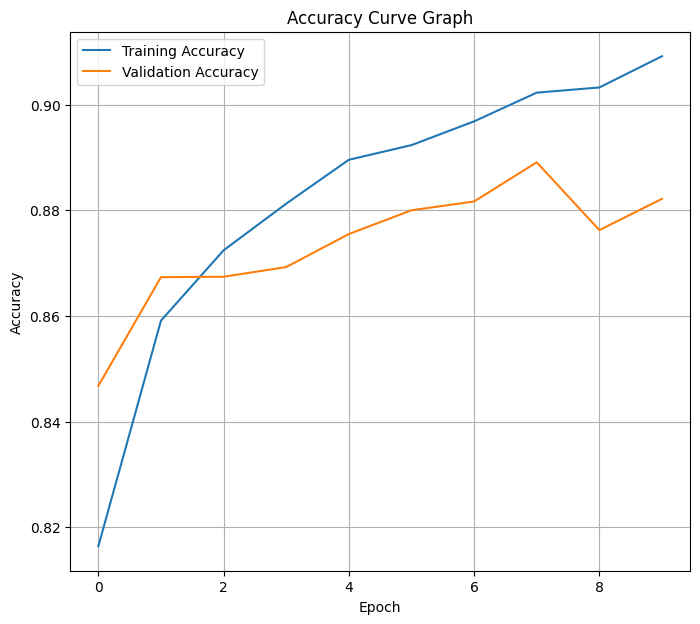

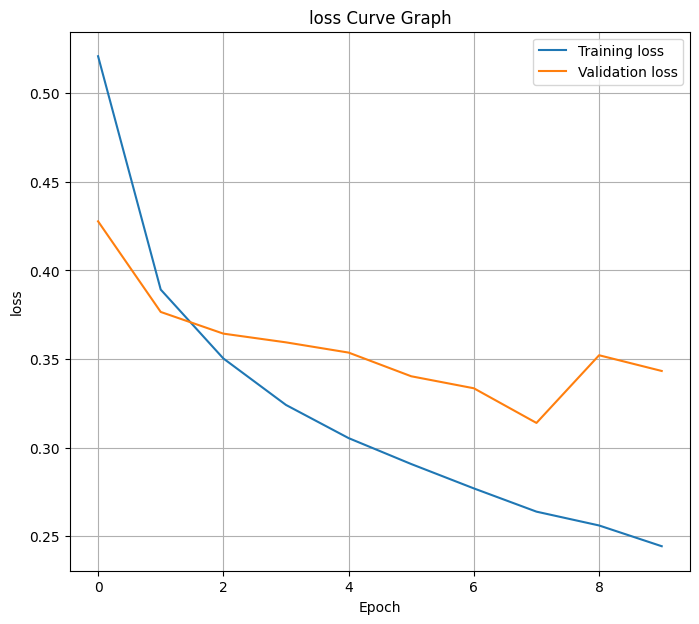

In [14]:
# --------------------------------------------------
# Model 1: Without Regularization
# --------------------------------------------------
model1 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history1 = model1.fit(
    x_train, y_train,
    epochs=10,
    validation_split=0.2
)

test_loss,test_acc = model1.evaluate(x_test,y_test)
print("\nTesting Accuracy : ",test_acc)
print("\nTesting Loss : ",test_loss)

plt.figure(figsize=(8,7))
plt.plot(history1.history['accuracy'],label='Training Accuracy')
plt.plot(history1.history['val_accuracy'],label='Validation Accuracy')
plt.grid(True)
plt.legend()

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve Graph")
plt.show()

plt.figure(figsize=(8,7))
plt.plot(history1.history['loss'],label='Training loss')
plt.plot(history1.history['val_loss'],label='Validation loss')
plt.grid(True)
plt.legend()

plt.xlabel("Epoch")
plt.ylabel("loss")
plt.title("loss Curve Graph")
plt.show()

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8125 - loss: 0.6670 - val_accuracy: 0.8452 - val_loss: 0.5460
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8451 - loss: 0.5245 - val_accuracy: 0.8382 - val_loss: 0.5374
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8520 - loss: 0.4916 - val_accuracy: 0.8462 - val_loss: 0.5173
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8570 - loss: 0.4737 - val_accuracy: 0.8552 - val_loss: 0.4817
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8621 - loss: 0.4605 - val_accuracy: 0.8428 - val_loss: 0.5074
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8648 - loss: 0.4506 - val_accuracy: 0.8463 - val_loss: 0.4952
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8668 - loss: 0.4427 - val_accuracy: 0.8662 - val_loss: 0.4407
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8683 - loss: 0.4343 - 

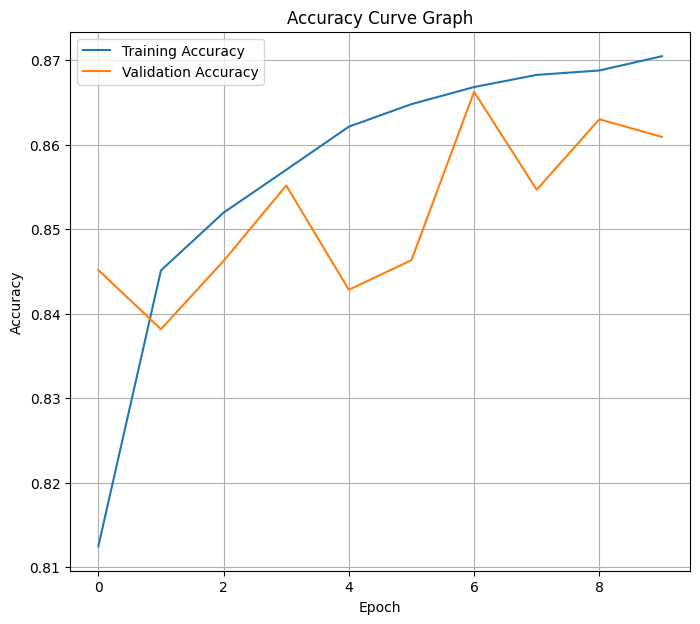

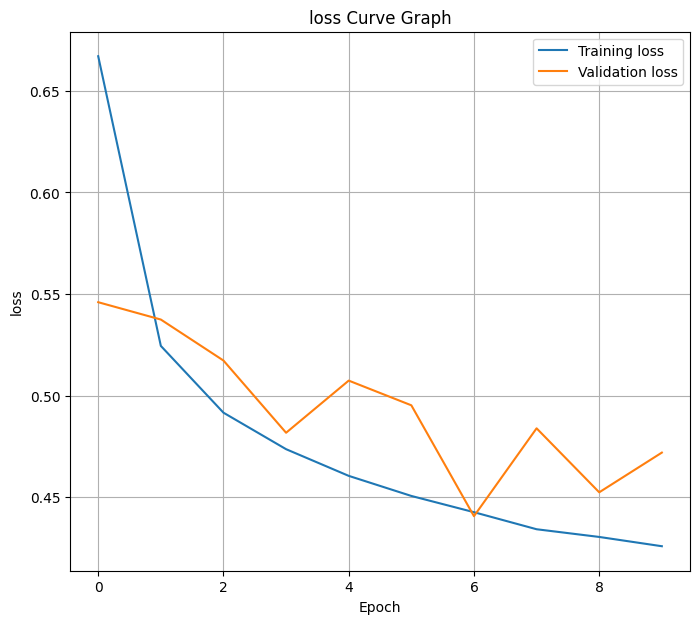

In [15]:
# --------------------------------------------------
# Model 2: L2 Regularization
# --------------------------------------------------
model2 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu',kernel_regularizer=l2(0.001)),
    Dense(10, activation='softmax')
])

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    x_train, y_train,
    epochs=10,
    validation_split=0.2
)
test_loss,test_acc = model2.evaluate(x_test,y_test)
print("\nTesting Accuracy : ",test_acc)
print("\nTesting Loss : ",test_loss)

plt.figure(figsize=(8,7))
plt.plot(history2.history['accuracy'],label='Training Accuracy')
plt.plot(history2.history['val_accuracy'],label='Validation Accuracy')
plt.grid(True)
plt.legend()

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve Graph")
plt.show()

plt.figure(figsize=(8,7))
plt.plot(history2.history['loss'],label='Training loss')
plt.plot(history2.history['val_loss'],label='Validation loss')
plt.grid(True)
plt.legend()

plt.xlabel("Epoch")
plt.ylabel("loss")
plt.title("loss Curve Graph")
plt.show()

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7986 - loss: 0.5695 - val_accuracy: 0.8556 - val_loss: 0.4081
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8448 - loss: 0.4252 - val_accuracy: 0.8602 - val_loss: 0.3831
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8580 - loss: 0.3916 - val_accuracy: 0.8608 - val_loss: 0.3840
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8654 - loss: 0.3675 - val_accuracy: 0.8758 - val_loss: 0.3501
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8706 - loss: 0.3544 - val_accuracy: 0.8760 - val_loss: 0.3473
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8745 - loss: 0.3411 - val_accuracy: 0.8775 - val_loss: 0.3418
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8777 - loss: 0.3292 - val_accuracy: 0.8818 - val_loss: 0.3257
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8802 - loss: 0.3177 - 

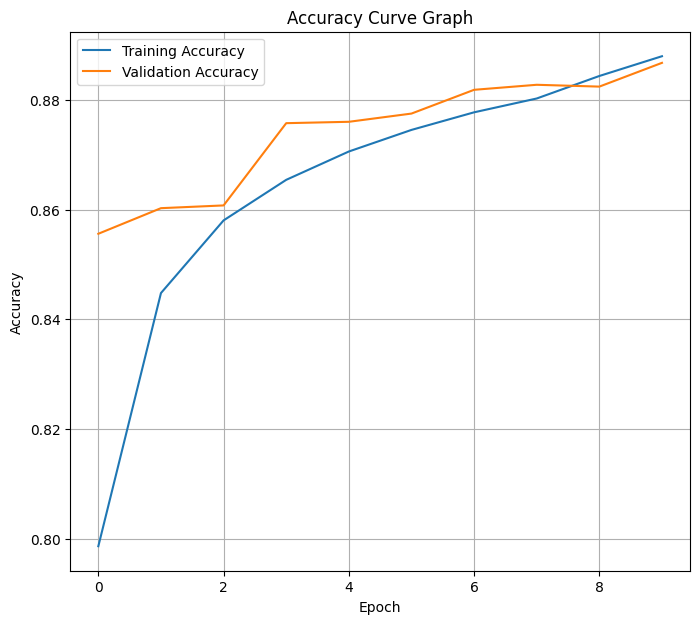

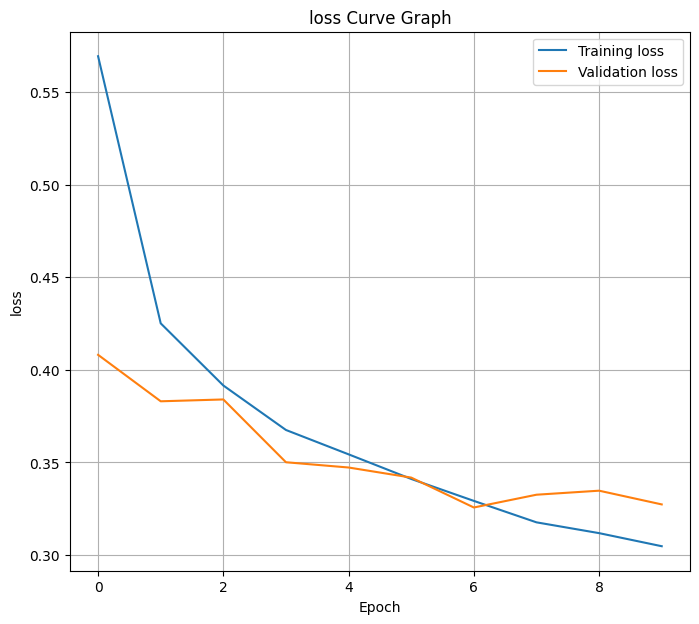

In [16]:
# --------------------------------------------------
# Model 3: Dropout
# --------------------------------------------------
model3 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(10, activation='softmax')
])

model3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history3 = model3.fit(
    x_train, y_train,
    epochs=10,
    validation_split=0.2
)

test_loss,test_acc = model3.evaluate(x_test,y_test)
print("\nTesting Accuracy : ",test_acc)
print("\nTesting Loss : ",test_loss)

plt.figure(figsize=(8,7))
plt.plot(history3.history['accuracy'],label='Training Accuracy')
plt.plot(history3.history['val_accuracy'],label='Validation Accuracy')
plt.grid(True)
plt.legend()

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve Graph")
plt.show()

plt.figure(figsize=(8,7))
plt.plot(history3.history['loss'],label='Training loss')
plt.plot(history3.history['val_loss'],label='Validation loss')
plt.grid(True)
plt.legend()

plt.xlabel("Epoch")
plt.ylabel("loss")
plt.title("loss Curve Graph")
plt.show()